In [15]:
# Importación de librerías
import numpy as np                             # para manejar listas de números
import matplotlib.pyplot as plt                # para graficar
from scipy.integrate import odeint             # para resolver ecuaciones diferenciales

plt.rcParams['figure.dpi'] = 110         # gráficas con buena resolución
print("Listo")

Listo


# Actividad Fundamental N.º 6 — Reporte técnico de simulación numérica e interpretación del comportamiento dinámico
Esta actividad corresponde a la **Fase 3: Simulación numérica e interpretación del comportamiento dinámico** del curso. En ella, el estudiante implementará de manera computacional las ecuaciones dinámicas obtenidas mediante el formalismo de Euler–Lagrange para un sistema robótico de dos grados de libertad. El objetivo es vincular el modelado matemático desarrollado en las fases anteriores con su simulación numérica, utilizando herramientas de programación científica en Python.

El estudiante deberá analizar el sistema físico proporcionado, definir correctamente los vectores de posición y velocidad, derivar el modelo matemático correspondiente y resolver numéricamente las ecuaciones diferenciales para distintos escenarios de condiciones iniciales y entradas de torque.

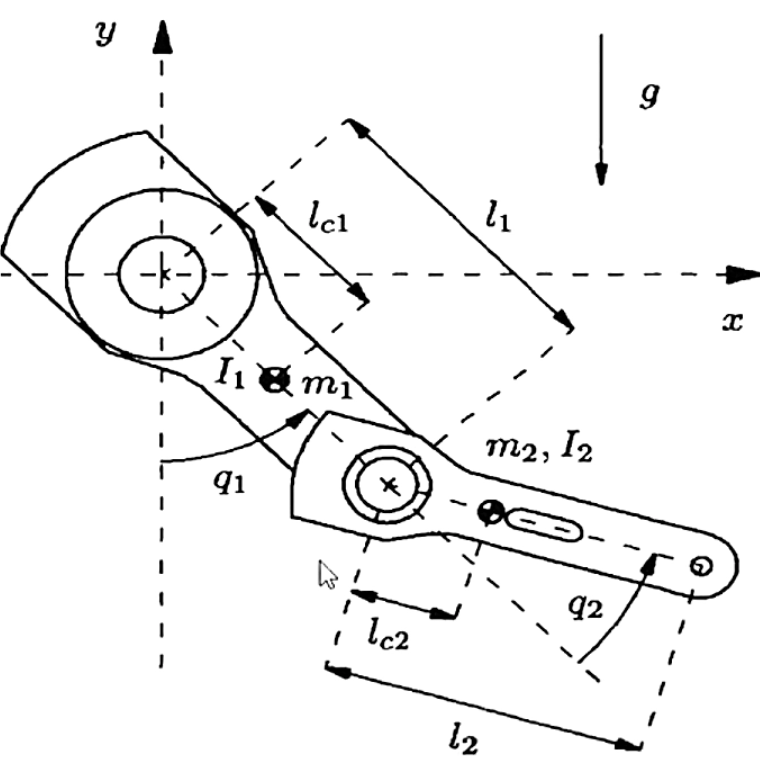

## Modelo matematico
**Vectores de posición y velocidad**
Eslabón 1:
  $$x_1 = l_{c1} \cos(q_1)$$   $$y_1 = l_{c1} \operatorname{sen}(q_1)$$   $$\dot{x}_1 = -l_{c1} \operatorname{sen}(q_1)\dot{q}_1$$   $$\dot{y}_1 = l_{c1} \cos(q_1)\dot{q}_1$$   $$v_1^2 = \dot{x}_1^2 + \dot{y}_1^2 = l_{c1}^2 \dot{q}_1^2$$   
  



  
Eslabón 2:   
  $$x_2 = l_1 \cos(q_1) + l_{c2} \cos(q_1 + q_2)$$   $$y_2 = l_1 \operatorname{sen}(q_1) + l_{c2} \operatorname{sen}(q_1 + q_2)$$   $$\dot{x}_2 = -l_1 \operatorname{sen}(q_1)\dot{q}_1 - l_{c2} \operatorname{sen}(q_1 + q_2)(\dot{q}_1 + \dot{q}_2)$$   $$\dot{y}_2 = l_1 \cos(q_1)\dot{q}_1 + l_{c2} \cos(q_1 + q_2)(\dot{q}_1 + \dot{q}_2)$$   $$v_2^2 = l_1^2 \dot{q}_1^2 + l_{c2}^2 (\dot{q}_1 + \dot{q}_2)^2 + 2 l_1 l_{c2} \cos(q_2)\dot{q}_1(\dot{q}_1 + \dot{q}_2)$$   
  



  Energía cinética ($K$):  
   $$K = \frac{1}{2}\alpha \dot{q}_1^2 + \frac{\delta}{2}(\dot{q}_1 + \dot{q}_2)^2 + \beta \cos(q_2)\dot{q}_1(\dot{q}_1 + \dot{q}_2)$$   
   


  Donde los parámetros constantes son:   
  $$\alpha = m_1 l_{c1}^2 + m_2 l_1^2 + I_1$$   $$\delta = m_2 l_{c2}^2 + I_2$$   $$\beta = m_2 l_1 l_{c2}$$




  Reescribiendo $K$ en términos de la matriz de inercia:   $$K = \frac{1}{2}M_{11}\dot{q}_1^2 + M_{12}\dot{q}_1\dot{q}_2 + \frac{1}{2}M_{22}\dot{q}_2^2$$   $$M_{11} = \alpha + \delta + 2\beta \cos(q_2)$$   $$M_{12} = \delta + \beta \cos(q_2)$$   $$M_{22} = \delta$$




  Derivadas parciales de la energía cinética:   $$\frac{\partial K}{\partial \dot{q}_1} = M_{11}\dot{q}_1 + M_{12}\dot{q}_2 = (\alpha + \delta + 2\beta \cos(q_2))\dot{q}_1 + (\delta + \beta \cos(q_2))\dot{q}_2$$   $$\frac{\partial K}{\partial \dot{q}_2} = M_{12}\dot{q}_1 + M_{22}\dot{q}_2 = (\delta + \beta \cos(q_2))\dot{q}_1 + \delta\dot{q}_2$$   $$\frac{\partial K}{\partial q_1} = 0$$   $$\frac{\partial K}{\partial q_2} = -\beta \operatorname{sen}(q_2)\dot{q}_1(\dot{q}_1 + \dot{q}_2) = -\beta \operatorname{sen}(q_2)\dot{q}_1^2 - \beta \operatorname{sen}(q_2)\dot{q}_1\dot{q}_2$$   Derivadas parciales de la energía potencial ($P$):   $$\frac{\partial P}{\partial q_1} = (m_1 l_{c1} + m_2 l_1)g \cos(q_1) + m_2 l_{c2} g \cos(q_1 + q_2)$$   $$\frac{\partial P}{\partial q_2} = m_2 l_{c2} g \cos(q_1 + q_2)$$



  Ecuaciones de Euler - Lagrange y forma matricial  
   $$\tau_i = \frac{d}{dt}\left(\frac{\partial K}{\partial \dot{q}_i}\right) - \frac{\partial K}{\partial q_i} + \frac{\partial P}{\partial q_i}$$   
   


  Para $q_1$:   
  $$\tau_1 = (\alpha + \delta + 2\beta \cos(q_2))\ddot{q}_1 + (\delta + \beta \cos(q_2))\ddot{q}_2 - 2\beta \operatorname{sen}(q_2)\dot{q}_1\dot{q}_2 - \beta \operatorname{sen}(q_2)\dot{q}_2^2 + (m_1 l_{c1} + m_2 l_1)g \cos(q_1) + m_2 l_{c2} g \cos(q_1 + q_2)$$



  Para $q_2$:
  $$\tau_2 = (\delta + \beta \cos(q_2))\ddot{q}_1 + \delta\ddot{q}_2 - \beta \operatorname{sen}(q_2)\dot{q}_1\dot{q}_2 - \left(-\beta \operatorname{sen}(q_2)\dot{q}_1^2 - \beta \operatorname{sen}(q_2)\dot{q}_1\dot{q}_2\right) + m_2 l_{c2} g \cos(q_1 + q_2)$$



  Representación matricial:  
   $$M(q)\ddot{q} + C(q,\dot{q})\dot{q} + G(q) = \tau$$   $$M(q) = \begin{bmatrix} \alpha + \delta + 2\beta \cos(q_2) & \delta + \beta \cos(q_2) \\ \delta + \beta \cos(q_2) & \delta \end{bmatrix}$$   $$C(q,\dot{q}) = \begin{bmatrix} -\beta \operatorname{sen}(q_2)\dot{q}_2 & -\beta \operatorname{sen}(q_2)(\dot{q}_1 + \dot{q}_2) \\ \beta \operatorname{sen}(q_2)\dot{q}_1 & 0 \end{bmatrix}$$   $$G(q) = \begin{bmatrix} (m_1 l_{c1} + m_2 l_1)g \cos(q_1) + m_2 l_{c2} g \cos(q_1 + q_2) \\ m_2 l_{c2} g \cos(q_1 + q_2) \end{bmatrix}$$

In [16]:
# Parámetros físicos y constantes agrupadas
m1 = 1.0    # masa del eslabón 1 (kg)
m2 = 1.0    # masa del eslabón 2 (kg)
l1 = 1.0    # longitud del eslabón 1 (m)
l2 = 1.0    # longitud del eslabón 2 (m)
lc1 = 0.5   # distancia al centro de masa 1 (m)
lc2 = 0.5   # distancia al centro de masa 2 (m)
I1 = (1/12) * m1 * l1**2  # momento de inercia centroidal 1 (kg·m^2)
I2 = (1/12) * m2 * l2**2  # momento de inercia centroidal 2 (kg·m^2)
g = 9.81    # aceleración gravitatoria (m/s^2)

# Constantes agrupadas definidas (alfa, delta, beta)
alpha = m1 * lc1**2 + m2 * l1**2 + I1
delta = m2 * lc2**2 + I2
beta  = m2 * l1 * lc2

In [17]:
# Definición del modelo dinámico
def modelo_manipulador(x, t, tau):
    q1, q2, qd1, qd2 = x
    qd = np.array([qd1, qd2])

    # Matriz de Inercia M(q)
    M11 = alpha + delta + 2 * beta * np.cos(q2)
    M12 = delta + beta * np.cos(q2)
    M22 = delta
    M = np.array([
        [M11, M12],
        [M12, M22]
    ])

    # Matriz de Coriolis C(q, qd)
    h = -beta * np.sin(q2)
    C = np.array([
        [2 * h * qd2, h * qd2],
        [h * qd1,     0.0    ]
    ])

    # Vector de Gravedad G(q)
    G1 = (m1 * lc1 + m2 * l1) * g * np.sin(q1) + m2 * lc2 * g * np.sin(q1 + q2)
    G2 = m2 * lc2 * g * np.sin(q1 + q2)
    G = np.array([G1, G2])

    # Ecuación de movimiento
    b = tau - (C @ qd) - G

    # Resolvemos la aceleración angular qdd
    qdd = np.linalg.solve(M, b)

    return [qd1, qd2, qdd[0], qdd[1]]

In [18]:
# Definición de escenarios (Caso a y Caso b) y tiempo
t = np.linspace(0, 5, 1000)  # Simulación de 0 a 5 segundos con 1000 puntos

In [19]:
# CASO A: q1(0) = 60°, q2(0) = 0°, sin torques (tau = [0, 0])
x0_a = [np.radians(60), 0.0, 0.0, 0.0]
tau_a = np.array([0.0, 0.0])
sol_a = odeint(modelo_manipulador, x0_a, t, args=(tau_a,))

In [20]:
# CASO B: q1(0) = 0°, q2(0) = 0°, con torques (tau1 = 10 Nm, tau2 = 1 Nm)
x0_b = [0.0, 0.0, 0.0, 0.0]
tau_b = np.array([10.0, 1.0])
sol_b = odeint(modelo_manipulador, x0_b, t, args=(tau_b,))

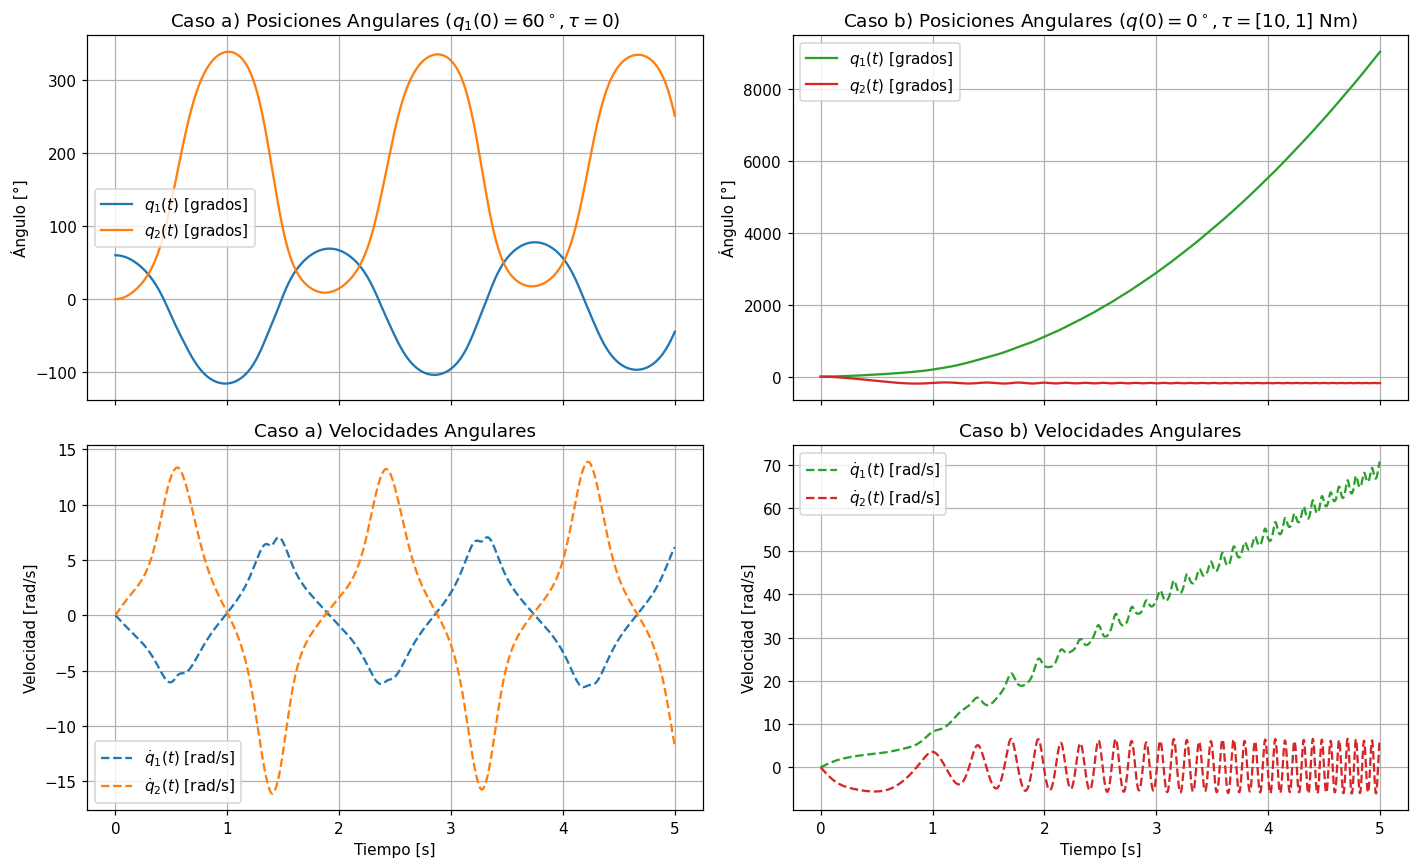

In [22]:
# Graficacion
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)

# Caso A - Posiciones
axes[0, 0].plot(t, np.degrees(sol_a[:, 0]), label=r'$q_1(t)$ [grados]', color='tab:blue')
axes[0, 0].plot(t, np.degrees(sol_a[:, 1]), label=r'$q_2(t)$ [grados]', color='tab:orange')
axes[0, 0].set_title(r'Caso a) Posiciones Angulares ($q_1(0)=60^\circ, \tau=0$)')
axes[0, 0].set_ylabel('Ángulo [°]')
axes[0, 0].legend(loc='best')
axes[0, 0].grid(True)

# Caso A - Velocidades
axes[1, 0].plot(t, sol_a[:, 2], label=r'$\dot{q}_1(t)$ [rad/s]', color='tab:blue', linestyle='--')
axes[1, 0].plot(t, sol_a[:, 3], label=r'$\dot{q}_2(t)$ [rad/s]', color='tab:orange', linestyle='--')
axes[1, 0].set_title('Caso a) Velocidades Angulares')
axes[1, 0].set_xlabel('Tiempo [s]')
axes[1, 0].set_ylabel('Velocidad [rad/s]')
axes[1, 0].legend(loc='best')
axes[1, 0].grid(True)

# Caso B - Posiciones
axes[0, 1].plot(t, np.degrees(sol_b[:, 0]), label=r'$q_1(t)$ [grados]', color='tab:green')
axes[0, 1].plot(t, np.degrees(sol_b[:, 1]), label=r'$q_2(t)$ [grados]', color='tab:red')
axes[0, 1].set_title(r'Caso b) Posiciones Angulares ($q(0)=0^\circ, \tau=[10, 1]$ Nm)')
axes[0, 1].set_ylabel('Ángulo [°]')
axes[0, 1].legend(loc='best')
axes[0, 1].grid(True)

# Caso B - Velocidades
axes[1, 1].plot(t, sol_b[:, 2], label=r'$\dot{q}_1(t)$ [rad/s]', color='tab:green', linestyle='--')
axes[1, 1].plot(t, sol_b[:, 3], label=r'$\dot{q}_2(t)$ [rad/s]', color='tab:red', linestyle='--')
axes[1, 1].set_title('Caso b) Velocidades Angulares')
axes[1, 1].set_xlabel('Tiempo [s]')
axes[1, 1].set_ylabel('Velocidad [rad/s]')
axes[1, 1].legend(loc='best')
axes[1, 1].grid(True)

plt.tight_layout()
plt.show()